# Relevance-preserving representations

Discrete bottleneck optimization exposes the tension between information retained about inputs and information retained about relevant labels. Multiple starts address local solutions without pretending to certify a global optimum.

[Interactive explorer](../docs/explorer.html) · [Measurement contracts](../docs/mathematical_contracts.md) · [Course proofs](../docs/course_coverage.md)

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

ROOT = next(
    p
    for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "src/information_lab").is_dir() and (p / "pyproject.toml").exists()
)
sys.path.insert(0, str(ROOT / "src"))


def query(family, **wanted):
    seed = wanted.pop("seed", 41)
    records = []
    for path in sorted((ROOT / "results/reference" / family).glob("*/run.json")):
        record = json.loads(path.read_text())
        if record["seed"] == seed and all(record["config"].get(k) == v for k, v in wanted.items()):
            records.append((record, path.parent))
    if not records:
        raise ValueError("No applicable recorded evidence")
    return records


def arrays(path):
    with np.load(path / "data.npz", allow_pickle=False) as archive:
        return {key: archive[key] for key in archive.files}


def measured(record):
    display(Markdown("**Recorded configuration**"))
    print(json.dumps(record["config"], indent=2))
    print(json.dumps(record["metrics"], indent=2))


def preview(record):
    key = record["config"]["id"] + "_s" + str(record["seed"])
    display(
        Image(
            filename=str(ROOT / "assets/experiments" / record["config"]["family"] / (key + ".png"))
        )
    )

In [2]:
from information_lab.bottleneck import multistart

pyx = np.array([0.05, 0.15, 0.2, 0.35, 0.65, 0.8, 0.85, 0.95])
joint = np.c_[1 - pyx, pyx] / 8
fit = multistart(joint, 3, 4, [41, 141, 241, 341, 441])
selected = fit["selected"]
print(
    "I(X;Z)",
    selected["i_input_bits"],
    "I(Y;Z)",
    selected["i_label_bits"],
    "objective",
    selected["objective_bits"],
)
print("Restart objectives", [r["objective_bits"] for r in fit["restarts"]])

I(X;Z) 0.7107362054052898 I(Y;Z) 0.25259247788310063 objective -0.2996337061271127
Restart objectives [-0.2996337061271127, -0.2996337061271125, -0.2996337061271124, -0.29963370612711215, -0.2996337061271124]


In [3]:
plt.imshow(selected["conditional"], aspect="auto", vmin=0, cmap="Blues")
plt.colorbar(label="Probability")
plt.xlabel("Representation state Z")
plt.ylabel("Input state X")
plt.show()

The self-consistent objective should decrease, and relevance cannot exceed the source-label MI by data processing. A low residual establishes a stationary local solution, not the best possible representation.

**Recorded configuration**

{
  "family": "bottleneck",
  "id": "clusters3_beta5",
  "clusters": 3,
  "beta": 4,
  "restarts": 5
}
{
  "i_input_bits": 0.7107362054052898,
  "i_label_bits": 0.25259247788310063,
  "objective_bits": -0.2996337061271127,
  "fixed_point_change": 7.031189075412669e-09,
  "converged": true,
  "iterations": 49,
  "seed": 41,
  "scope": "Self-consistent IB updates find a local stationary solution. A small residual is not a global-optimum certificate. Compare independently initialized restarts.",
  "selected_restart": 0,
  "source_label_mi": 0.3619416469761976
}


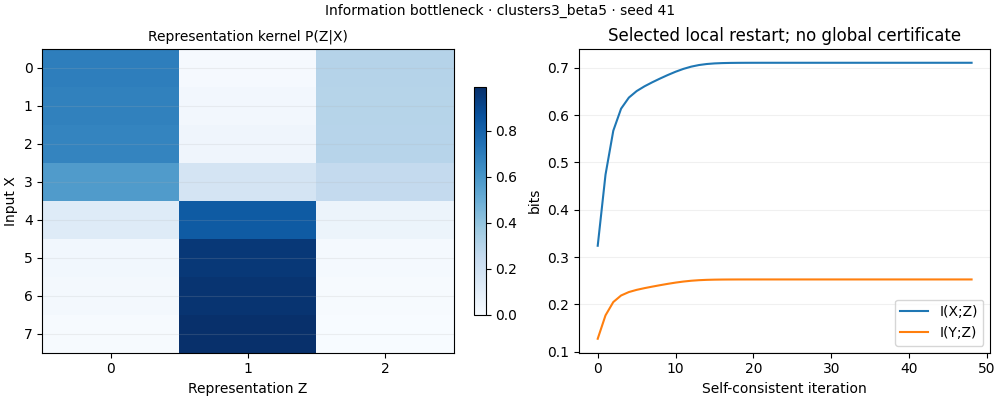

In [4]:
assert np.max(np.diff(selected["trace"][:, 2])) <= 1e-8
record, path = query("bottleneck", clusters=3, beta=4)[0]
measured(record)
preview(record)

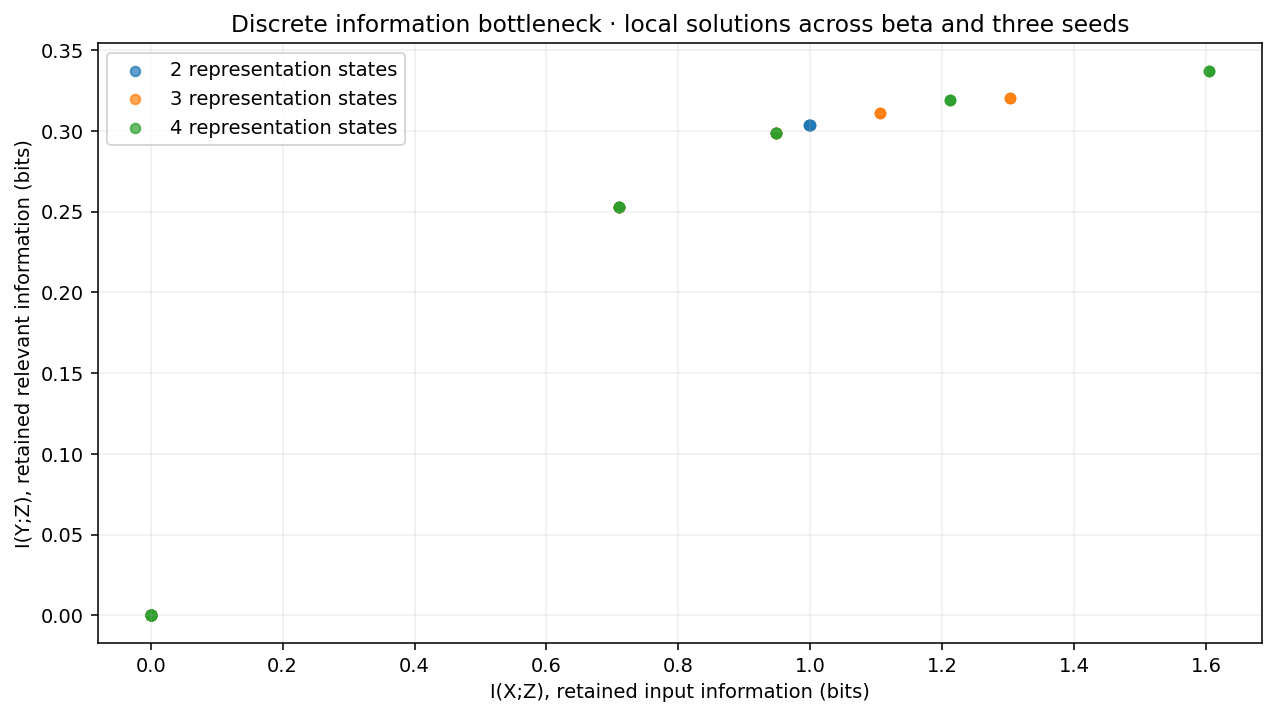

In [5]:
display(Image(filename=str(ROOT / "assets/previews/bottleneck_comparison.png")))